# 16.11 - Agent visual review: model miss and explicit negative

This batch reviews source-train photos at original resolution. The prior occlusal model score prioritizes inspection only. Every target receives `present`, `absent`, or `uncertain`; an omitted box never implies absence. The labels are school-project visual research annotations by Codex, not clinical diagnoses.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
root=Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root==root.parent: raise RuntimeError("Project root not found")
    root=root.parent
base=root / "data/processed/alignment_omni_frontal_candidates"
queue=pd.read_csv(base / "review_queue.csv",dtype={"source_image_id":str,"sha256":str}).set_index("source_image_id")
ranking=pd.read_csv(root / "docs/reports/alignment/omni_candidate_probe/ranking.csv",dtype={"source_image_id":str}).set_index("source_image_id")
excluded=set(pd.read_csv(root / "docs/reports/alignment/omni_frontal_candidate_audit/conservative_train_exclusions.csv",dtype=str).source_image_id)

## 1. Record observed target states

The first image is a missed midline gap in the zero-score sample. The second has a visible upper central gap. The third is an explicitly reviewed visual negative for both target findings. Other ambiguous findings stay uncertain.

In [2]:
reviews=pd.DataFrame([
    ("201875201810241","frontal","present","uncertain","visible upper central separation; zero-score model miss"),
    ("202243202207131","frontal","present","uncertain","visible upper central separation"),
    ("201883201809131","frontal","absent","absent","upper central contact and no obvious anterior overlap"),
],columns=["source_image_id","view_review","diastema_review","crowding_review","visual_reason"])
reviews["reviewer"]="Codex visual review"
reviews["review_state"]="agent_visual_provisional"
for row in reviews.itertuples():
    source=queue.loc[row.source_image_id]
    assert source["split"]=="train" and row.source_image_id not in excluded
    assert hashlib.sha256((root / source["image_path"]).read_bytes()).hexdigest()==source["sha256"]
reviews["diastema_probe_score"]=[ranking.loc[id,"diastema_probe_score"] for id in reviews.source_image_id]
display(reviews)

,source_image_id,view_review,diastema_review,crowding_review,visual_reason,reviewer,review_state,diastema_probe_score
0,201875201810241,frontal,present,uncertain,visible upper central separation; zero-score m...,Codex visual review,agent_visual_provisional,0.00000
1,202243202207131,frontal,present,uncertain,visible upper central separation,Codex visual review,agent_visual_provisional,0.10072
2,201883201809131,frontal,absent,absent,upper central contact and no obvious anterior ...,Codex visual review,agent_visual_provisional,0.00000


## 2. Draw target boxes

Follow the published rule of boxing both upper central incisors for a midline gap. No box is created for the reviewed negative. Coordinates are original image pixels.

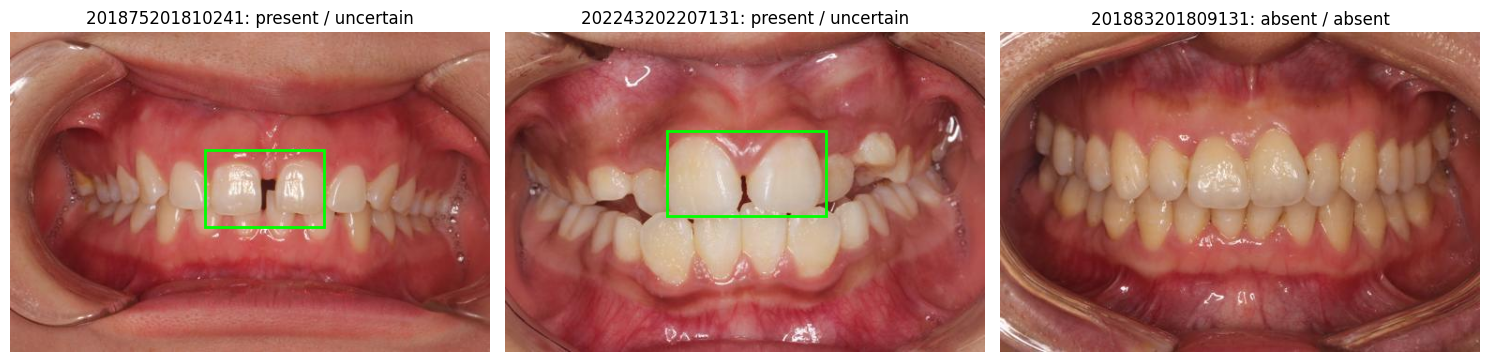

In [3]:
boxes=pd.DataFrame([
    ("201875201810241","upper_midline_diastema",207,125,334,207),
    ("202243202207131","upper_midline_diastema",172,105,342,195),
],columns=["source_image_id","target","x_min","y_min","x_max","y_max"])
boxes["reviewer"]="Codex visual review"
boxes["review_state"]="agent_visual_provisional"
for row in boxes.itertuples():
    source=queue.loc[row.source_image_id]
    assert 0<=row.x_min<row.x_max<=int(source["width"]) and 0<=row.y_min<row.y_max<=int(source["height"])
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,row in zip(axes,reviews.itertuples()):
    ax.imshow(Image.open(root / queue.loc[row.source_image_id,"image_path"]))
    for box in boxes[boxes.source_image_id==row.source_image_id].itertuples():
        ax.add_patch(plt.Rectangle((box.x_min,box.y_min),box.x_max-box.x_min,box.y_max-box.y_min,fill=False,color="lime",lw=2))
    ax.set_title(f"{row.source_image_id}: {row.diastema_review} / {row.crowding_review}")
    ax.axis("off")
fig.tight_layout()
out=root / "docs/reports/alignment/agent_visual_pilot"
fig.savefig(out / "active_review_batch.png",dpi=150)
plt.show(); plt.close(fig)

## 3. Persist provenance

Keep this batch separate from the original source annotations and the locked validation. Neither model scores nor source `TM` labels are treated as ground truth.

In [4]:
for name,frame in (("active_review_states.csv",reviews),("active_review_boxes.csv",boxes)):
    path=out / name
    if path.exists():
        assert pd.read_csv(path,dtype={"source_image_id":str}).equals(frame),f"Existing review differs: {path}"
    else: frame.to_csv(path,index=False)
    print("Saved",path)
print("Explicit negative images:",sum((reviews.diastema_review=="absent") & (reviews.crowding_review=="absent")))

Saved C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\active_review_states.csv
Saved C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\active_review_boxes.csv
Explicit negative images: 1
